In [2]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("environmental_monthly_clean.csv")

Statistiques et qualité

In [4]:
display(df.describe(include='all').T)
print('Manquants :');display(df.isna().mean().sort_values(ascending=False).head(15))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
site_code,4992,64,knt-kes,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reporting_month,4992,78,2019-01-01,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean_temperature_c,4992.0,NaN,NaN,NaN,26.377073,1.672062,21.3,25.19,26.35,27.6125,32.0
rainfall_mm,4992.0,NaN,NaN,NaN,159.89403,74.901939,5.0,95.7,156.25,221.7,384.3
mean_humidity_pct,4992.0,NaN,NaN,NaN,75.841847,7.248342,56.7,70.3,75.9,81.5,96.4
vegetation_cover_pct,4982.0,NaN,NaN,NaN,61.014211,13.997015,15.0,52.7,62.3,70.9,98.0
habitat_disturbance_index,4992.0,NaN,NaN,NaN,30.364423,16.358109,0.0,17.9,29.4,41.4,86.8
pesticide_index,4977.0,NaN,NaN,NaN,25.016395,16.26636,0.0,11.6,25.2,37.5,77.3
land_use_category,4992,8,mixed_forest,1482,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_exception_code,204,2,heavy_rain,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Manquants :


weather_exception_code       0.959135
pesticide_index              0.003005
vegetation_cover_pct         0.002003
mean_temperature_c           0.000000
reporting_month              0.000000
site_code                    0.000000
rainfall_mm                  0.000000
habitat_disturbance_index    0.000000
mean_humidity_pct            0.000000
land_use_category            0.000000
data_completeness_pct        0.000000
dtype: float64

Profils environnementaux des sites

,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct
site_code,,,,,,,
avl-abg,27.25,160.82,74.52,65.60,13.26,34.67,96.18
avl-aru,26.23,142.94,77.21,50.65,49.93,31.50,95.89
avl-bvm,27.14,154.08,76.87,67.98,20.16,9.38,95.82
avl-bwk,26.17,129.66,77.84,67.03,24.60,10.63,95.87
avl-der,27.17,145.06,75.18,69.82,9.45,13.80,96.17
avl-ecj,26.79,151.69,76.01,71.34,32.67,41.13,95.81
avl-fnm,27.64,163.23,75.95,53.77,21.45,13.95,96.56
avl-fnq,26.68,164.49,74.75,46.13,41.85,52.21,96.18
avl-grb,27.07,169.78,76.95,33.83,65.62,48.16,95.67


,habitat_disturbance_index
site_code,
knt-ggn,72.796154
avl-grb,65.623077
avl-trp,64.551282
knt-dmj,51.944872
knt-lum,51.494872
knt-jqg,50.083333
avl-aru,49.932051
avl-nfr,49.356410
knt-yrx,47.170513


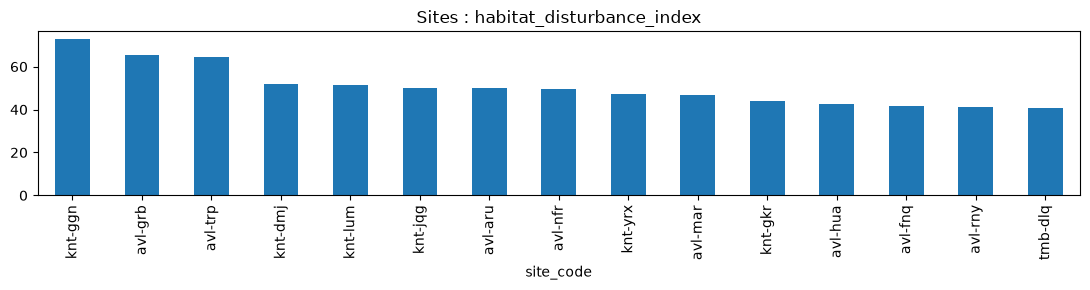

,pesticide_index
site_code,
avl-fnq,52.212821
avl-kar,50.842308
tmb-dlq,50.651316
avl-grb,48.161538
knt-gkr,44.135897
avl-hua,43.571795
avl-yau,43.374359
knt-bme,42.435065
avl-rbc,41.646753


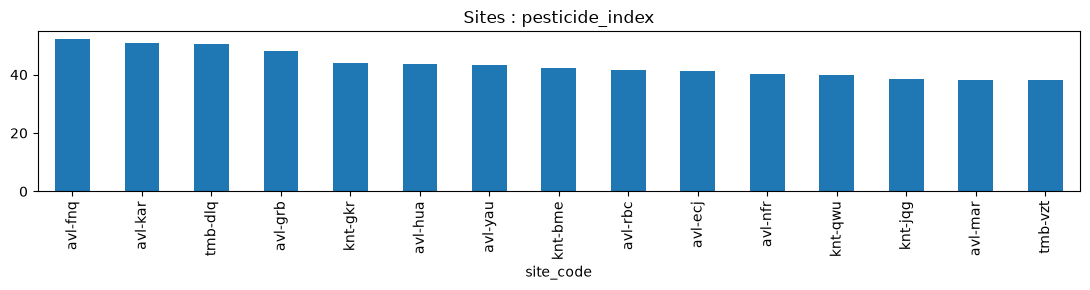

,vegetation_cover_pct
site_code,
avl-mar,83.506410
knt-tlq,81.807692
tmb-nac,80.067949
knt-bme,79.235065
tmb-qcb,78.248718
knt-chp,76.344872
tmb-ayq,76.180769
tmb-vzt,75.196154
tmb-hql,72.491026


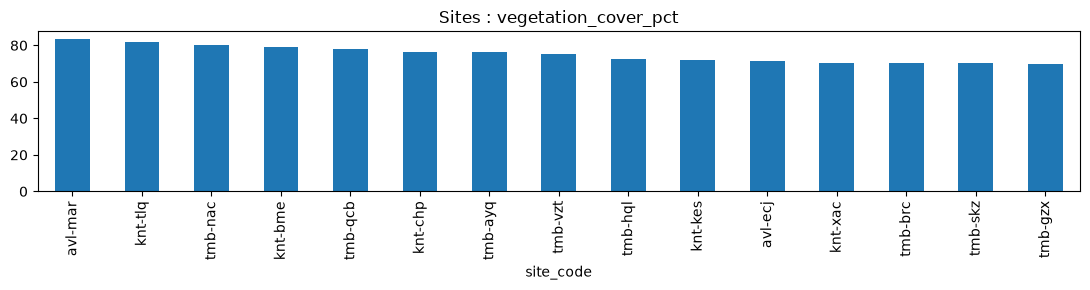

In [5]:
features=["mean_temperature_c","rainfall_mm","mean_humidity_pct","vegetation_cover_pct","habitat_disturbance_index","pesticide_index","data_completeness_pct"]
display(df.groupby("site_code")[features].mean().round(2).head(20))
for col in ["habitat_disturbance_index","pesticide_index","vegetation_cover_pct"]:
 s=df.groupby("site_code")[col].mean().sort_values(ascending=False)
 display(s.head(12).rename(col).to_frame())
 s.head(15).plot(kind="bar",figsize=(11,3),title="Sites : "+col);plt.tight_layout();plt.show()

Changements brusques au sein de chaque site

In [6]:
df=df.sort_values(["site_code","reporting_month"]).copy()
for col in ["habitat_disturbance_index","pesticide_index","vegetation_cover_pct","data_completeness_pct"]:
 df["delta_"+col]=df.groupby("site_code")[col].diff()
 col_delta="delta_"+col
 print("Variations absolues les plus fortes :",col)
 display(df.loc[df[col_delta].abs().nlargest(12).index,["site_code","reporting_month",col,col_delta]])
print("Ces variations peuvent être saisonnières ou liées à des erreurs : vérifier le contexte.")

Variations absolues les plus fortes : habitat_disturbance_index


,site_code,reporting_month,habitat_disturbance_index,delta_habitat_disturbance_index
4868,tmb-qcb,2021-09-01,5.0,-50.2
1924,knt-tex,2023-05-01,47.7,47.4
4880,tmb-qcb,2022-09-01,6.2,-47.1
4904,tmb-qcb,2024-09-01,13.1,-46.7
1880,knt-tex,2019-09-01,0.0,-45.7
1936,knt-tex,2024-05-01,43.2,38.8
4892,tmb-qcb,2023-09-01,9.9,-38.6
4856,tmb-qcb,2020-09-01,13.0,-38.5
4864,tmb-qcb,2021-05-01,57.0,38.3
1940,knt-tex,2024-09-01,4.4,-37.8


Variations absolues les plus fortes : pesticide_index


,site_code,reporting_month,pesticide_index,delta_pesticide_index
841,knt-gkr,2024-02-01,77.3,64.9
2302,avl-aru,2022-05-01,0.0,-59.1
856,knt-gkr,2025-05-01,12.7,-56.5
2272,avl-aru,2019-11-01,6.2,-54.1
2320,avl-aru,2023-11-01,9.5,-52.1
808,knt-gkr,2021-05-01,14.4,-48.9
1615,knt-qwu,2023-08-01,67.8,47.8
1609,knt-qwu,2023-02-01,61.0,44.8
2335,avl-aru,2025-02-01,55.0,43.6
2332,avl-aru,2024-11-01,5.2,-43.5


Variations absolues les plus fortes : vegetation_cover_pct


,site_code,reporting_month,vegetation_cover_pct,delta_vegetation_cover_pct
3603,tmb-hvd,2020-04-01,58.3,-23.2
2169,avl-trp,2024-04-01,39.1,22.2
3305,avl-hua,2021-06-01,44.0,21.6
3868,tmb-wyt,2022-11-01,81.3,21.2
3088,avl-bvm,2022-11-01,58.7,-21.1
965,knt-jak,2021-06-01,70.6,21.0
776,knt-yrx,2025-03-01,35.7,20.7
4828,tmb-wql,2024-11-01,70.6,20.7
1848,knt-vxr,2023-07-01,84.4,19.6
253,avl-mar,2020-08-01,98.0,19.5


Variations absolues les plus fortes : data_completeness_pct


,site_code,reporting_month,data_completeness_pct,delta_data_completeness_pct
2795,avl-rbc,2024-06-01,100.0,14.4
4159,tmb-uvf,2021-02-01,86.4,-13.3
4160,tmb-uvf,2021-03-01,99.4,13.0
2224,avl-nfr,2022-05-01,100.0,12.9
3392,avl-fnm,2022-03-01,99.0,12.7
467,avl-orr,2025-06-01,87.7,-12.3
3262,avl-sey,2024-05-01,100.0,12.3
4222,tmb-hfr,2019-11-01,97.5,12.0
1542,knt-ggn,2024-01-01,88.1,-11.9
2285,avl-aru,2020-12-01,88.0,-11.7


Ces variations peuvent être saisonnières ou liées à des erreurs : vérifier le contexte.


Anomalies multivariées et concentration par site

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
X=df[features].replace([np.inf,-np.inf],np.nan);valid=X.notna().all(axis=1)
model=IsolationForest(n_estimators=300,contamination=0.03,random_state=42)
Xs=StandardScaler().fit_transform(X.loc[valid]);df["anomaly_score"]=np.nan;df["anomaly"]=pd.NA
df.loc[valid,"anomaly_score"]=model.fit(Xs).score_samples(Xs)
df.loc[valid,"anomaly"]=model.predict(Xs)
a=df.loc[df.anomaly==-1].sort_values("anomaly_score")
display(a[["site_code","reporting_month","anomaly_score"]+features].head(25))
display(a.groupby("site_code").size().sort_values(ascending=False).head(20).rename("nb_anomalies").to_frame())

,site_code,reporting_month,anomaly_score,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct
2413,avl-grb,2025-02-01,-0.643251,29.20,58.5,72.0,24.9,64.0,56.1,88.2
1542,knt-ggn,2024-01-01,-0.624665,27.51,47.5,70.7,29.7,69.7,0.0,88.1
2341,avl-grb,2019-02-01,-0.620018,27.63,45.2,61.3,28.4,71.1,54.8,94.0
1548,knt-ggn,2024-07-01,-0.616296,28.04,170.7,93.2,27.3,79.3,0.0,95.6
1498,knt-ggn,2020-05-01,-0.612703,28.33,179.1,85.8,25.2,86.8,0.0,100.0
1530,knt-ggn,2023-01-01,-0.602391,27.04,75.2,70.1,15.6,81.3,0.0,100.0
2408,avl-grb,2024-09-01,-0.602270,25.46,310.2,84.5,37.3,70.4,50.9,91.2
1509,knt-ggn,2021-04-01,-0.602008,27.94,54.6,81.6,32.5,79.5,0.0,92.3
1411,knt-dmj,2019-08-01,-0.600733,24.98,291.2,93.4,67.2,47.4,0.0,88.1
2138,avl-trp,2021-09-01,-0.600648,24.43,338.9,92.3,38.4,67.0,33.5,95.4


,nb_anomalies
site_code,
knt-ggn,55
avl-grb,28
avl-trp,15
knt-dmj,6
knt-jqg,6
tmb-nac,6
avl-mar,4
knt-bme,3
tmb-dlq,3


KMeans

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
scores={}
for k in range(2,7):
 labels=KMeans(n_clusters=k,random_state=42,n_init=10).fit_predict(Xs)
 scores[k]=silhouette_score(Xs,labels,sample_size=min(2000,len(Xs)),random_state=42)
print(scores);k=max(scores,key=scores.get)
df["cluster"]=pd.NA;df.loc[valid,"cluster"]=KMeans(n_clusters=k,random_state=42,n_init=10).fit_predict(Xs)
display(df.loc[valid].groupby("cluster")[features].mean().round(2))

{2: 0.1977795617957171, 3: 0.18254685187704262, 4: 0.1484968914717855, 5: 0.12854270661580144, 6: 0.13302889175860452}


,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct
cluster,,,,,,,
0,25.79,220.85,81.49,66.52,29.50,25.60,95.97
1,26.95,101.13,70.40,55.65,31.22,24.41,95.96


KMeans distingue deux profils environnementaux.

Le premier présente davantage de précipitations , une humidité plus élevée  et une couverture végétale plus importante.

Le second correspond à des conditions plus sèches, avec 101,13 mm de précipitations et 70,40 % d'humidité en moyenne.

Les indices de perturbation de l'habitat et de pesticides restent relativement proches entre les deux groupes.

## Investigation environnementale de KNT-KES

In [9]:
df["reporting_month"] = pd.to_datetime(
    df["reporting_month"]
)

kes_env = df[
    df["site_code"].str.lower() == "knt-kes"
].copy()

kes_env["annee"] = kes_env["reporting_month"].dt.year
kes_env["mois"] = kes_env["reporting_month"].dt.month

display(
    kes_env[
        (kes_env["annee"] == 2024)
        & (kes_env["mois"].between(1, 7))
    ][[
        "reporting_month",
        "mean_temperature_c",
        "rainfall_mm",
        "habitat_disturbance_index",
        "pesticide_index",
        "weather_exception_code",
        "data_completeness_pct"
    ]]
)

,reporting_month,mean_temperature_c,rainfall_mm,habitat_disturbance_index,pesticide_index,weather_exception_code,data_completeness_pct
60,2024-01-01,25.94,71.3,12.5,17.4,NaN,91.8
61,2024-02-01,26.02,61.2,14.6,17.6,NaN,93.7
62,2024-03-01,27.28,118.4,26.3,27.4,NaN,93.1
63,2024-04-01,28.19,140.6,7.9,19.4,NaN,92.1
64,2024-05-01,26.15,246.2,17.7,36.8,NaN,95.7
65,2024-06-01,27.18,231.3,24.9,31.8,NaN,100.0
66,2024-07-01,26.74,240.0,13.4,24.8,NaN,97.0


À KNT-KES, les précipitations augmentent entre avril et mai 2024, passant de 140,6 à 246,2 mm. L'indice de pesticides augmente également, de 19,4 à 36,8.

En revanche, l'indice de perturbation de l'habitat reste relativement modéré, avec une valeur de 17,7 en mai.

La complétude des données atteint 95,7 %, ce qui ne suggère pas un manque massif d'informations environnementales.

Ces résultats montrent certains changements environnementaux en mai 2024, mais aucun ne suffit à lui seul à expliquer la baisse de 84 % de l'activité des chauves-souris.

# Comparer les conditions de mai sur toutes les années


In [10]:
mai_env = kes_env[
    kes_env["mois"] == 5
].sort_values("annee")

display(
    mai_env[[
        "annee",
        "rainfall_mm",
        "habitat_disturbance_index",
        "pesticide_index",
        "data_completeness_pct"
    ]]
)

,annee,rainfall_mm,habitat_disturbance_index,pesticide_index,data_completeness_pct
4,2019,198.9,21.1,17.1,93.9
16,2020,222.0,17.4,24.8,97.2
28,2021,209.6,20.3,13.1,99.4
40,2022,214.1,17.2,26.1,96.8
52,2023,189.0,24.9,30.7,99.8
64,2024,246.2,17.7,36.8,95.7
76,2025,184.4,25.0,20.9,91.1


### Bilan des analyses et hypothèse retenue

L'analyse des données environnementales de KNT-KES en mai 2024 montre :

- **Des précipitations maximales** par rapport aux autres mois de mai étudiés (246,2 mm).
- **Un indice de pesticides également maximal** (36,8).
- **Un indice de perturbation de l'habitat relativement modéré** (17,7), inférieur à celui de mai 2023 (24,9) et mai 2025 (25,0).
- **Aucune concentration particulière d'anomalies environnementales** à KNT-KES selon Isolation Forest.

**Hypothèse :** les précipitations et les pesticides ont pu contribuer à la baisse d'activité observée en mai 2024. Cependant, les indicateurs environnementaux ne permettent pas d'expliquer à eux seuls la chute de 84 % des observations de chauves-souris.

L'hypothèse d'une perturbation liée à une intervention humaine reste donc plausible, notamment au regard des traces suspectes relevées dans le rapport d'incident EFR-510088.